<a href="https://colab.research.google.com/github/Srashti1801/SRASHTIHCL1/blob/main/Employee_attirition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Employee Attrition Analysis Using Python

## 1. Introduction

Employee attrition refers to employees leaving an organisation. It is a common challenge for companies because it can increase recruitment costs and affect productivity.

In this project, we will analyse employee data using Python. We will study different factors such as age, salary, department, working hours and years of experience to understand their relationship with employee attrition risk.

## 2. Objectives

- To understand the employee attrition risk score.
- To identify factors associated with employee attrition risk.
- To compare attrition risk across different departments and work modes.
- To identify employees who may require attention.

## 3. Tools and Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Import python libraries..

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Upload raw data

In [ ]:
df = pd.read_csv('attrition_data.csv')

### Display the dataset..

In [ ]:
df.head()

,Employee_ID,Department,City,Work_Mode,Job_Level,Age,Years_At_Company,Monthly_Salary_INR,Avg_Weekly_Hours,Commute_Distance_Km,Last_Appraisal_Date,Attrition_Risk_Score
0,E1090,HR,Hyderabad,Onsite,Junior,26,2.5,30500.0,55.2,9.8,2025-03-23,66.2
1,E1017,Engineering,Bengaluru,Onsite,Junior,32,4.5,27000.0,48.5,1.6,2025-10-27,65.1
2,E1242,Engineering,Hyderabad,Onsite,Junior,29,4.7,33500.0,44.2,4.0,2025-12-13,58.1
3,E1159,HR,Bengaluru,Hybrid,Junior,28,2.5,25000.0,40.1,7.9,2025-05-01,50.0
4,E1226,Operations,Delhi,Remote,Senior,42,8.4,120000.0,54.6,14.0,2025-07-15,37.8


### Check the Dataset size...

In [ ]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (255, 12)


### Check the column names..

In [ ]:
df.columns

Index(['Employee_ID', 'Department', 'City', 'Work_Mode', 'Job_Level', 'Age',
       'Years_At_Company', 'Monthly_Salary_INR', 'Avg_Weekly_Hours',
       'Commute_Distance_Km', 'Last_Appraisal_Date', 'Attrition_Risk_Score'],
      dtype='object')

#### Check the Dataset information..

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Employee_ID           255 non-null    object 
 1   Department            255 non-null    object 
 2   City                  255 non-null    object 
 3   Work_Mode             249 non-null    object 
 4   Job_Level             255 non-null    object 
 5   Age                   255 non-null    int64  
 6   Years_At_Company      255 non-null    float64
 7   Monthly_Salary_INR    250 non-null    float64
 8   Avg_Weekly_Hours      251 non-null    float64
 9   Commute_Distance_Km   255 non-null    float64
 10  Last_Appraisal_Date   250 non-null    object 
 11  Attrition_Risk_Score  255 non-null    float64
dtypes: float64(5), int64(1), object(6)
memory usage: 24.0+ KB


#### Statistical summary of the dataset

In [ ]:
df.describe()

,Age,Years_At_Company,Monthly_Salary_INR,Avg_Weekly_Hours,Commute_Distance_Km,Attrition_Risk_Score
count,255.000000,255.000000,250.000000,251.000000,255.000000,255.000000
mean,31.760784,3.990196,60662.000000,47.548606,14.958039,50.571373
std,13.324893,2.552400,35075.345693,5.497056,9.586018,14.331091
min,-27.000000,0.300000,19500.000000,35.000000,1.500000,0.000000
25%,27.000000,2.200000,33500.000000,43.950000,7.850000,42.300000
50%,31.000000,3.300000,50750.000000,47.300000,13.300000,50.900000
75%,36.000000,5.450000,71000.000000,51.100000,20.800000,60.300000
max,214.000000,13.600000,197000.000000,63.500000,52.700000,90.100000


### Find Missing Values...

In [ ]:
df.isnull().sum()

,0
Employee_ID,0
Department,0
City,0
Work_Mode,6
Job_Level,0
Age,0
Years_At_Company,0
Monthly_Salary_INR,5
Avg_Weekly_Hours,4
Commute_Distance_Km,0


### Find Duplicate values...

In [ ]:
df.duplicated().sum()

np.int64(5)

### Check data...

In [ ]:
print("Departments:")
print(df['Department'].value_counts())
print("\nWork Modes:")
print(df['Work_Mode'].value_counts())
print("\nJob Levels:")
print(df['Job_Level'].value_counts())
print("\nCities:")
print(df['City'].value_counts())

Departments:
Department
Engineering    102
Sales           52
Operations      48
HR              27
Finance         26
Name: count, dtype: int64

Work Modes:
Work_Mode
Onsite    130
Hybrid     86
Remote     33
Name: count, dtype: int64

Job Levels:
Job_Level
Junior     105
Mid         98
Senior      36
Manager     16
Name: count, dtype: int64

Cities:
City
Bengaluru      75
Hyderabad      54
Pune           51
Chennai        38
Delhi          30
bengaluru       2
  Pune          1
CHENNAI         1
 Bengaluru      1
HYDERABAD       1
Pune            1
Name: count, dtype: int64


In [ ]:
print("Minimum Age:", df['Age'].min())
print("Maximum Age:", df['Age'].max())
print("Minimum Salary:", df['Monthly_Salary_INR'].min())
print("Maximum Salary:", df['Monthly_Salary_INR'].max())
print("Minimum Risk Score:", df['Attrition_Risk_Score'].min())
print("Maximum Risk Score:", df['Attrition_Risk_Score'].max())

Minimum Age: -27
Maximum Age: 214
Minimum Salary: 19500.0
Maximum Salary: 197000.0
Minimum Risk Score: 0.0
Maximum Risk Score: 90.1


### Data Cleaning...

In [ ]:
df_clean = df.copy()
print("Original dataset shape:", df.shape)
print("Cleaning dataset shape:", df_clean.shape)

Original dataset shape: (255, 12)
Cleaning dataset shape: (255, 12)


In [ ]:
df_clean = df_clean.drop_duplicates()
print("Duplicates remaining:", df_clean.duplicated().sum())
print("Dataset shape:", df_clean.shape)

Duplicates remaining: 0
Dataset shape: (250, 12)


In [ ]:
df_clean['Work_Mode'] = df_clean['Work_Mode'].fillna(df_clean['Work_Mode'].mode()[0])

In [ ]:
df_clean['Monthly_Salary_INR'] = df_clean['Monthly_Salary_INR'].fillna(df_clean['Monthly_Salary_INR'].median())

In [ ]:
df_clean['Avg_Weekly_Hours'] = df_clean['Avg_Weekly_Hours'].fillna(df_clean['Avg_Weekly_Hours'].median())

In [ ]:
df_clean['Last_Appraisal_Date'] = pd.to_datetime(df_clean['Last_Appraisal_Date'],errors='coerce')

In [ ]:
df_clean['City'] = (df_clean['City'].str.strip().str.title())
print(df_clean['City'].value_counts())

City
Bengaluru    77
Hyderabad    55
Pune         52
Chennai      37
Delhi        29
Name: count, dtype: int64


In [ ]:
df_clean.loc[~df_clean['Age'].between(18, 65),'Age'] = np.nan
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())
print("Minimum age:", df_clean['Age'].min())
print("Maximum age:", df_clean['Age'].max())

Minimum age: 22.0
Maximum age: 45.0


In [ ]:
print("Final Dataset Shape:", df_clean.shape)
print("\nMissing Values:")
print(df_clean.isnull().sum())
print("\nDuplicate Records:")
print(df_clean.duplicated().sum())
print("\nData Types:")
print(df_clean.dtypes)

Final Dataset Shape: (250, 12)

Missing Values:
Employee_ID             0
Department              0
City                    0
Work_Mode               0
Job_Level               0
Age                     0
Years_At_Company        0
Monthly_Salary_INR      0
Avg_Weekly_Hours        0
Commute_Distance_Km     0
Last_Appraisal_Date     5
Attrition_Risk_Score    0
dtype: int64

Duplicate Records:
0

Data Types:
Employee_ID                     object
Department                      object
City                            object
Work_Mode                       object
Job_Level                       object
Age                            float64
Years_At_Company               float64
Monthly_Salary_INR             float64
Avg_Weekly_Hours               float64
Commute_Distance_Km            float64
Last_Appraisal_Date     datetime64[ns]
Attrition_Risk_Score           float64
dtype: object


In [ ]:
df_clean.to_csv('attrition_data_clean.csv',index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


### Creating New Columns...

In [ ]:
df_clean['Annual_Salary'] = (df_clean['Monthly_Salary_INR'] * 12)
df_clean[['Employee_ID','Monthly_Salary_INR','Annual_Salary']].head()

,Employee_ID,Monthly_Salary_INR,Annual_Salary
0,E1090,30500.0,366000.0
1,E1017,27000.0,324000.0
2,E1242,33500.0,402000.0
3,E1159,25000.0,300000.0
4,E1226,120000.0,1440000.0


In [ ]:
def categorize_risk(score):
    if score < 40:
        return 'Low Risk'
    elif score < 70:
        return 'Medium Risk'
    else:
        return 'High Risk'
df_clean['Risk_Category'] = (df_clean['Attrition_Risk_Score'].apply(categorize_risk))
df_clean[['Employee_ID','Attrition_Risk_Score','Risk_Category']].head()

,Employee_ID,Attrition_Risk_Score,Risk_Category
0,E1090,66.2,Medium Risk
1,E1017,65.1,Medium Risk
2,E1242,58.1,Medium Risk
3,E1159,50.0,Medium Risk
4,E1226,37.8,Low Risk


In [ ]:
def categorize_experience(years):
    if years <= 2:
        return 'Fresher'
    elif years <= 5:
        return 'Mid-Level'
    else:
        return 'Experienced'

df_clean['Experience_Group'] = (df_clean['Years_At_Company'].apply(categorize_experience))
df_clean[['Employee_ID','Years_At_Company','Experience_Group']].head()

,Employee_ID,Years_At_Company,Experience_Group
0,E1090,2.5,Mid-Level
1,E1017,4.5,Mid-Level
2,E1242,4.7,Mid-Level
3,E1159,2.5,Mid-Level
4,E1226,8.4,Experienced


In [ ]:
print("New Columns Created Successfully!")
print(df_clean[['Annual_Salary','Risk_Category','Experience_Group']].head())
print("\nRisk Category Distribution:")
print(df_clean['Risk_Category'].value_counts())
print("\nExperience Group Distribution:")
print(df_clean['Experience_Group'].value_counts())

New Columns Created Successfully!
   Annual_Salary Risk_Category Experience_Group
0       366000.0   Medium Risk        Mid-Level
1       324000.0   Medium Risk        Mid-Level
2       402000.0   Medium Risk        Mid-Level
3       300000.0   Medium Risk        Mid-Level
4      1440000.0      Low Risk      Experienced

Risk Category Distribution:
Risk_Category
Medium Risk    186
Low Risk        49
High Risk       15
Name: count, dtype: int64

Experience Group Distribution:
Experience_Group
Mid-Level      123
Experienced     72
Fresher         55
Name: count, dtype: int64


In [ ]:
print("Final Dataset Shape:", df_clean.shape)
df_clean.head()

Final Dataset Shape: (250, 15)


,Employee_ID,Department,City,Work_Mode,Job_Level,Age,Years_At_Company,Monthly_Salary_INR,Avg_Weekly_Hours,Commute_Distance_Km,Last_Appraisal_Date,Attrition_Risk_Score,Annual_Salary,Risk_Category,Experience_Group
0,E1090,HR,Hyderabad,Onsite,Junior,26.0,2.5,30500.0,55.2,9.8,2025-03-23,66.2,366000.0,Medium Risk,Mid-Level
1,E1017,Engineering,Bengaluru,Onsite,Junior,32.0,4.5,27000.0,48.5,1.6,2025-10-27,65.1,324000.0,Medium Risk,Mid-Level
2,E1242,Engineering,Hyderabad,Onsite,Junior,29.0,4.7,33500.0,44.2,4.0,2025-12-13,58.1,402000.0,Medium Risk,Mid-Level
3,E1159,HR,Bengaluru,Hybrid,Junior,28.0,2.5,25000.0,40.1,7.9,2025-05-01,50.0,300000.0,Medium Risk,Mid-Level
4,E1226,Operations,Delhi,Remote,Senior,42.0,8.4,120000.0,54.6,14.0,2025-07-15,37.8,1440000.0,Low Risk,Experienced


In [ ]:
df_clean.to_csv('attrition_data_enhanced.csv',index=False)
print("Enhanced dataset saved successfully!")

Enhanced dataset saved successfully!


In [ ]:
df_enhanced = pd.read_csv('attrition_data_enhanced.csv')
print(df_enhanced.shape)
df_enhanced.head()

(250, 15)


,Employee_ID,Department,City,Work_Mode,Job_Level,Age,Years_At_Company,Monthly_Salary_INR,Avg_Weekly_Hours,Commute_Distance_Km,Last_Appraisal_Date,Attrition_Risk_Score,Annual_Salary,Risk_Category,Experience_Group
0,E1090,HR,Hyderabad,Onsite,Junior,26.0,2.5,30500.0,55.2,9.8,2025-03-23,66.2,366000.0,Medium Risk,Mid-Level
1,E1017,Engineering,Bengaluru,Onsite,Junior,32.0,4.5,27000.0,48.5,1.6,2025-10-27,65.1,324000.0,Medium Risk,Mid-Level
2,E1242,Engineering,Hyderabad,Onsite,Junior,29.0,4.7,33500.0,44.2,4.0,2025-12-13,58.1,402000.0,Medium Risk,Mid-Level
3,E1159,HR,Bengaluru,Hybrid,Junior,28.0,2.5,25000.0,40.1,7.9,2025-05-01,50.0,300000.0,Medium Risk,Mid-Level
4,E1226,Operations,Delhi,Remote,Senior,42.0,8.4,120000.0,54.6,14.0,2025-07-15,37.8,1440000.0,Low Risk,Experienced


#### Data Analysis and Visualization...

In [ ]:
df_enhanced = pd.read_csv('attrition_data_enhanced.csv')
print("Dataset loaded successfully!")
print("Shape:", df_enhanced.shape)

Dataset loaded successfully!
Shape: (250, 15)


In [ ]:
print("Average Risk Score:",df_enhanced['Attrition_Risk_Score'].mean())
print("Minimum Risk Score:",df_enhanced['Attrition_Risk_Score'].min())
print("Maximum Risk Score:",df_enhanced['Attrition_Risk_Score'].max())
print("Median Risk Score:",df_enhanced['Attrition_Risk_Score'].median())

Average Risk Score: 50.51239999999999
Minimum Risk Score: 0.0
Maximum Risk Score: 90.1
Median Risk Score: 50.849999999999994


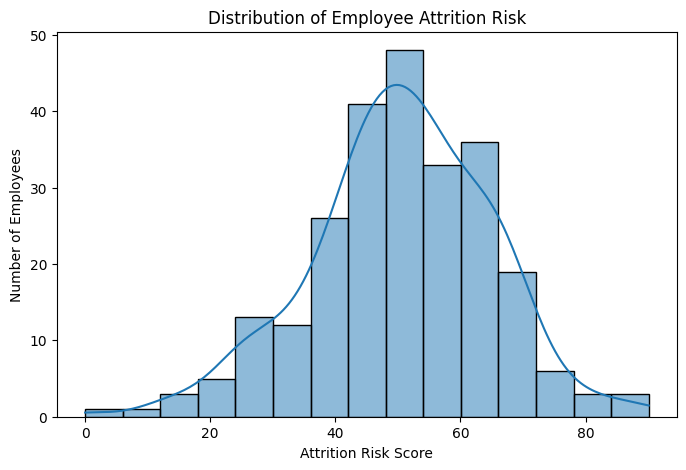

In [ ]:

plt.figure(figsize=(8, 5))
sns.histplot(df_enhanced['Attrition_Risk_Score'],bins=15,kde=True)
plt.title('Distribution of Employee Attrition Risk')
plt.xlabel('Attrition Risk Score')
plt.ylabel('Number of Employees')
plt.savefig('chart1_risk_distribution.png',dpi=300, bbox_inches='tight')
plt.show()

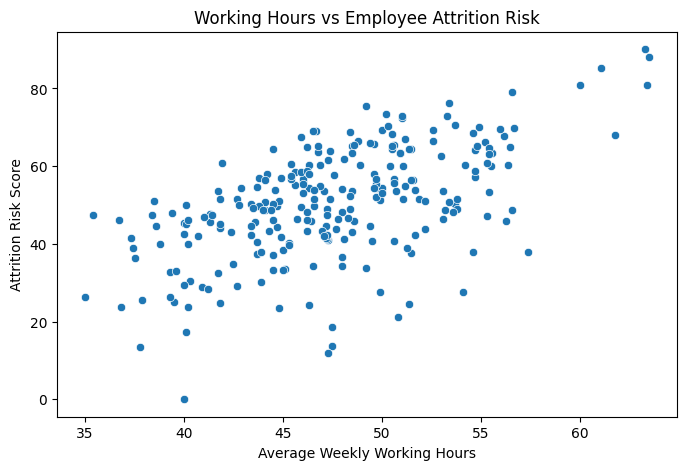

In [ ]:

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_enhanced,x='Avg_Weekly_Hours',y='Attrition_Risk_Score')
plt.title('Working Hours vs Employee Attrition Risk')
plt.xlabel('Average Weekly Working Hours')
plt.ylabel('Attrition Risk Score')
plt.savefig('chart2_working_hours.png',dpi=300, bbox_inches='tight')
plt.show()

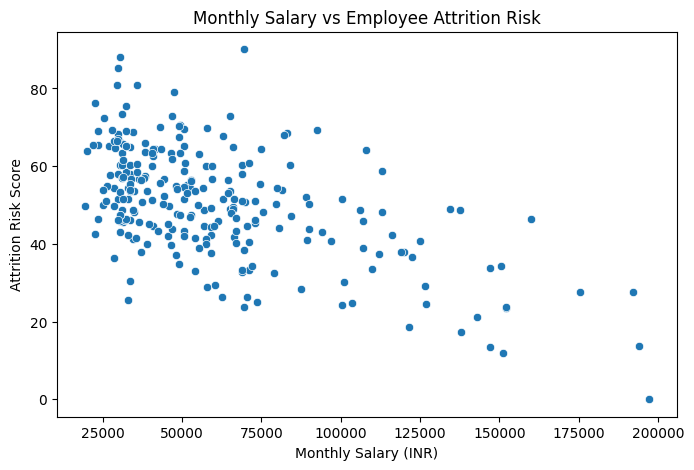

In [ ]:

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_enhanced,x='Monthly_Salary_INR',y='Attrition_Risk_Score')
plt.title('Monthly Salary vs Employee Attrition Risk')
plt.xlabel('Monthly Salary (INR)')
plt.ylabel('Attrition Risk Score')
plt.savefig('chart3_salary.png',dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
department_risk = df_enhanced.groupby('Department')['Attrition_Risk_Score'].mean()
print(department_risk)

Department
Engineering    48.515842
Finance        52.738462
HR             50.588462
Operations     50.352083
Sales          53.563265
Name: Attrition_Risk_Score, dtype: float64


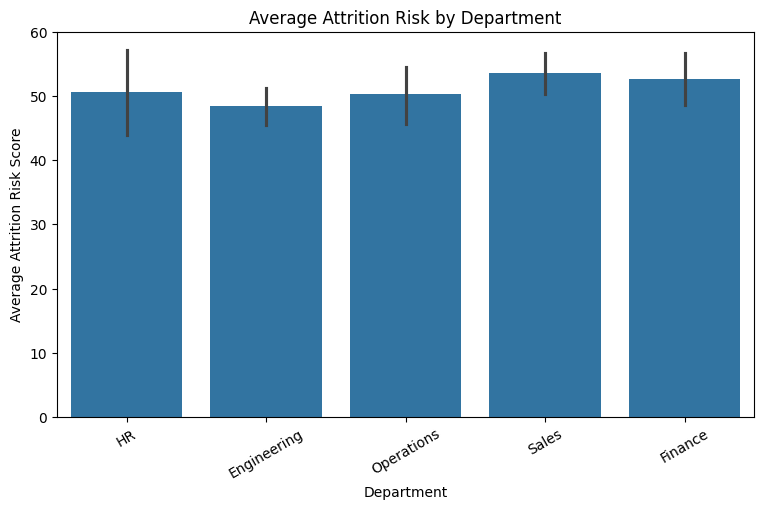

In [ ]:

plt.figure(figsize=(9, 5))
sns.barplot(data=df_enhanced,x='Department',y='Attrition_Risk_Score',estimator='mean')
plt.title('Average Attrition Risk by Department')
plt.xlabel('Department')
plt.ylabel('Average Attrition Risk Score')
plt.xticks(rotation=30)
plt.savefig('chart4_department_risk.png',dpi=300, bbox_inches='tight')
plt.show()

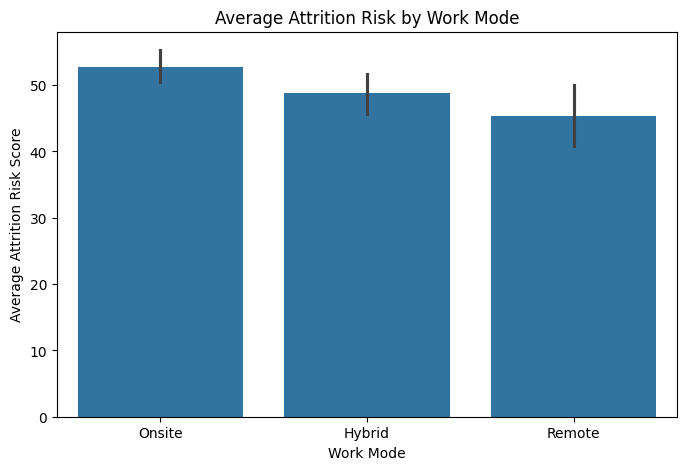

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_enhanced,x='Work_Mode',y='Attrition_Risk_Score',estimator='mean')
plt.title('Average Attrition Risk by Work Mode')
plt.xlabel('Work Mode')
plt.ylabel('Average Attrition Risk Score')
plt.savefig('chart5_work_mode.png',dpi=300, bbox_inches='tight')
plt.show()

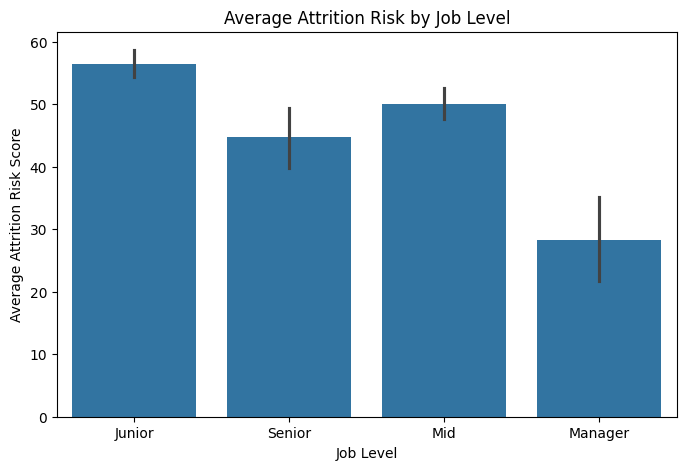

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_enhanced,x='Job_Level',y='Attrition_Risk_Score',estimator='mean')
plt.title('Average Attrition Risk by Job Level')
plt.xlabel('Job Level')
plt.ylabel('Average Attrition Risk Score')
plt.savefig('chart6_job_level.png',dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
print("Employee Risk Categories:")
print(df_enhanced['Risk_Category'].value_counts())

Employee Risk Categories:
Risk_Category
Medium Risk    186
Low Risk        49
High Risk       15
Name: count, dtype: int64


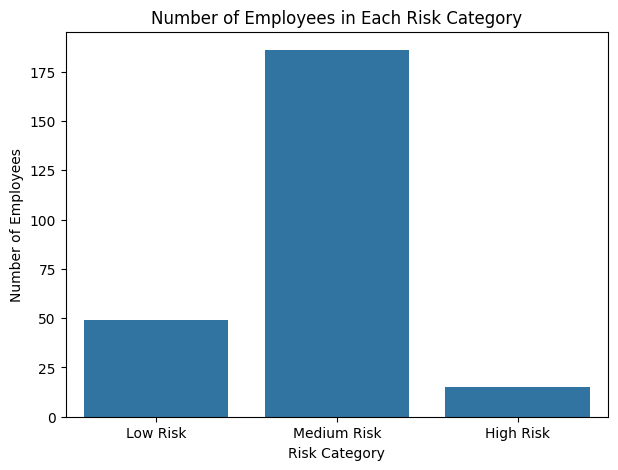

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df_enhanced,x='Risk_Category',order=['Low Risk', 'Medium Risk', 'High Risk'])
plt.title('Number of Employees in Each Risk Category')
plt.xlabel('Risk Category')
plt.ylabel('Number of Employees')
plt.savefig('chart7_risk_categories.png',dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
high_risk_employees = df_enhanced[df_enhanced['Risk_Category'] == 'High Risk']
print("Employees Requiring Attention:")
print(high_risk_employees[['Employee_ID','Department','Job_Level','Attrition_Risk_Score','Risk_Category']])

Employees Requiring Attention:
    Employee_ID   Department Job_Level  Attrition_Risk_Score Risk_Category
14        E1041  Engineering    Junior                  72.3     High Risk
23        E1150      Finance       Mid                  70.2     High Risk
26        E1180   Operations       Mid                  79.1     High Risk
39        E1152  Engineering    Junior                  76.3     High Risk
53        E1244  Engineering    Junior                  80.8     High Risk
87        E1059   Operations       Mid                  73.0     High Risk
94        E1230        Sales       Mid                  70.5     High Risk
114       E1179   Operations    Junior                  85.2     High Risk
116       E1231  Engineering    Junior                  73.3     High Risk
125       E1233   Operations    Junior                  88.2     High Risk
131       E1019  Engineering       Mid                  73.0     High Risk
152       E1162           HR       Mid                  90.1     High

In [ ]:
import os
os.makedirs('images', exist_ok=True)
print("Images folder created successfully!")

Images folder created successfully!


In [ ]:
import shutil
for i in range(1, 8):
    filename = f'chart{i}_'
    matches = [
        f for f in os.listdir('.')
        if f.startswith(filename) and f.endswith('.png')
    ]
    for file in matches:
        shutil.move(file, os.path.join('images', file))

print("All charts saved in images folder!")

All charts saved in images folder!


Key Insights from Employee Attrition Analysis

After analysing the data of 250 employees, the following insights were observed:

1. Risk Categories: Most employees fall under the Medium Risk category (approximately 186 employees). Around 49 employees are in Low Risk, while 15 employees are in High Risk.

2. Working Hours: The chart shows that employees working longer weekly hours generally tend to have higher attrition risk scores. This may indicate that workload is an important factor to examine.

3. Monthly Salary: Employees with higher monthly salaries generally show lower risk scores in the dataset. However, salary alone does not determine attrition risk.

4. Work Mode: Onsite employees have the highest average risk score, followed by Hybrid employees. Remote employees have the lowest average risk score.

5. Job Level: Junior employees show the highest average attrition risk, while Managers show the lowest. This suggests that junior employees may need more support and career development opportunities.

6. Department: Sales has the highest average attrition risk, followed by Finance. Engineering has the lowest average risk among the departments shown.

Overall Finding

The analysis suggests that working hours, salary, work mode, job level, and department may be associated with employee attrition risk. The organisation should pay particular attention to junior employees, employees working long hours, and teams with higher average risk scores.

In [ ]:
original_columns = [
    'Employee_ID', 'Department', 'City', 'Work_Mode',
    'Job_Level', 'Age', 'Years_At_Company',
    'Monthly_Salary_INR', 'Avg_Weekly_Hours',
    'Commute_Distance_Km', 'Last_Appraisal_Date',
    'Attrition_Risk_Score']
df_enhanced[original_columns].to_csv(
    'attrition_data_clean.csv', index=False)
print("Cleaned CSV saved successfully!")

Cleaned CSV saved successfully!
